# Vehicle Speed Prediction - V1.1

So in V1.0 I got the basic Decision Tree working. Now in this version I want to try out a bunch of different models and see which one actually performs the best. I'll also do proper cross validation, hyperparameter tuning, and compare everything side by side.

**Models I'm testing:**
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Support Vector Machine (SVM)
- K-Nearest Neighbors

## 1. Loading and Understanding the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

# load the data
df = pd.read_csv('car_speed_data.csv')
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"\nColumn names: {list(df.columns)}")
df.head(8)

Dataset: 500 rows, 9 columns

Column names: ['speed', 'engine_temp', 'fuel_level', 'tire_pressure', 'car_age', 'weather_condition', 'driver_experience', 'traffic_condition', 'action']


,speed,engine_temp,fuel_level,tire_pressure,car_age,weather_condition,driver_experience,traffic_condition,action
0,9,119.665945,87.230502,33.689042,9,1,2,0,very slow
1,117,66.157384,86.088681,30.290136,4,0,1,0,really fast
2,75,60.628500,18.018498,33.509206,6,0,2,0,normal
3,64,119.782186,63.553022,31.456687,2,1,0,0,normal
4,76,66.681758,97.645855,32.081484,14,1,0,0,normal
5,47,111.752996,63.179729,32.697589,8,0,0,1,very slow
6,85,66.402186,41.522551,33.878393,3,2,0,1,fast
7,89,69.675065,81.488332,33.120005,8,1,0,2,fast


In [2]:
# check for issues
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print(f"\nData types:\n{df.dtypes}")
print(f"\nTarget distribution:\n{df['action'].value_counts()}")

Missing values: 0
Duplicates: 0

Data types:
speed                  int64
engine_temp          float64
fuel_level           float64
tire_pressure        float64
car_age                int64
weather_condition      int64
driver_experience      int64
traffic_condition      int64
action                object
dtype: object

Target distribution:
action
very slow      208
fast            89
really fast     87
normal          73
slow            43
Name: count, dtype: int64


## 2. EDA - Understanding Feature Relationships

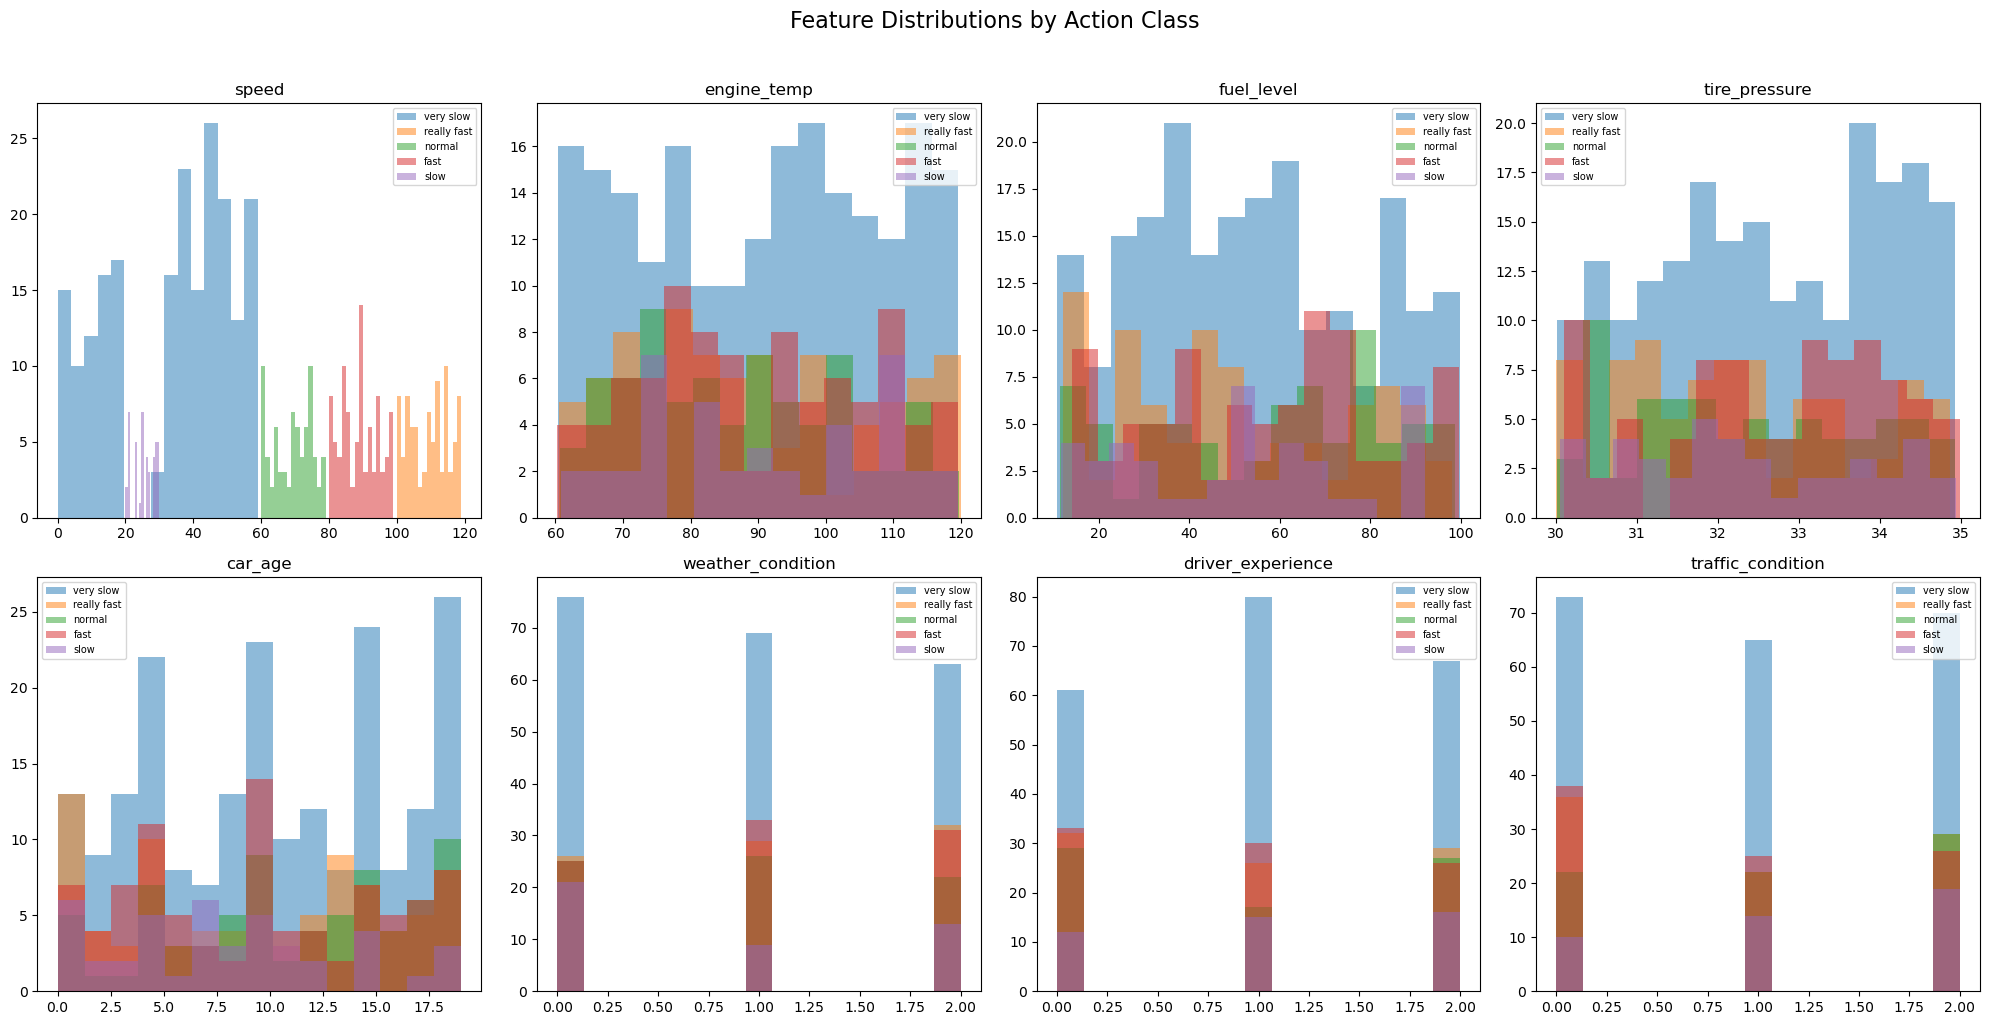

In [3]:
# feature distributions with respect to action classes
features = ['speed', 'engine_temp', 'fuel_level', 'tire_pressure',
            'car_age', 'weather_condition', 'driver_experience', 'traffic_condition']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, feat in enumerate(features):
    for action in df['action'].unique():
        subset = df[df['action'] == action]
        axes[i].hist(subset[feat], alpha=0.5, label=action, bins=15)
    axes[i].set_title(feat)
    axes[i].legend(fontsize=7)

plt.suptitle('Feature Distributions by Action Class', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

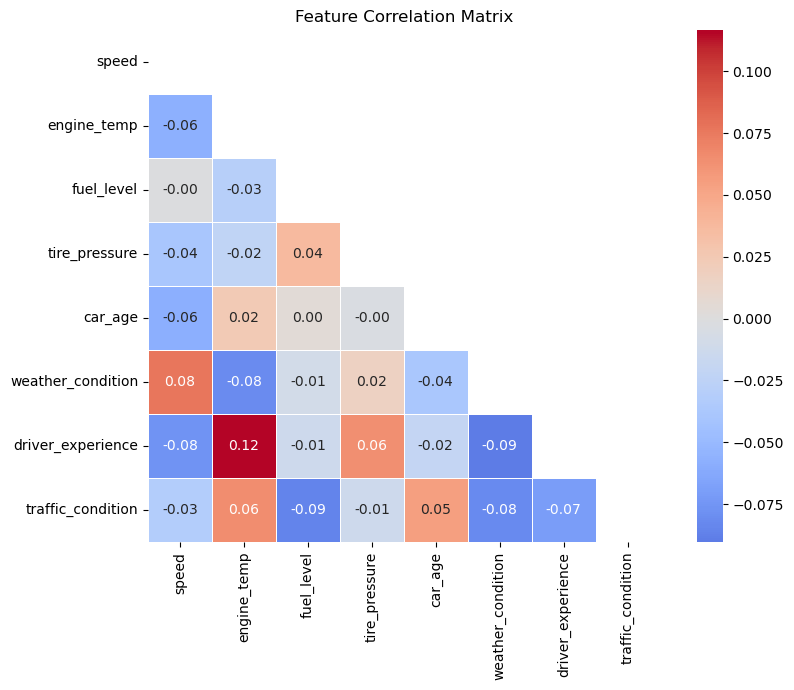

In [4]:
# correlation matrix
plt.figure(figsize=(9, 7))
corr = df.drop('action', axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

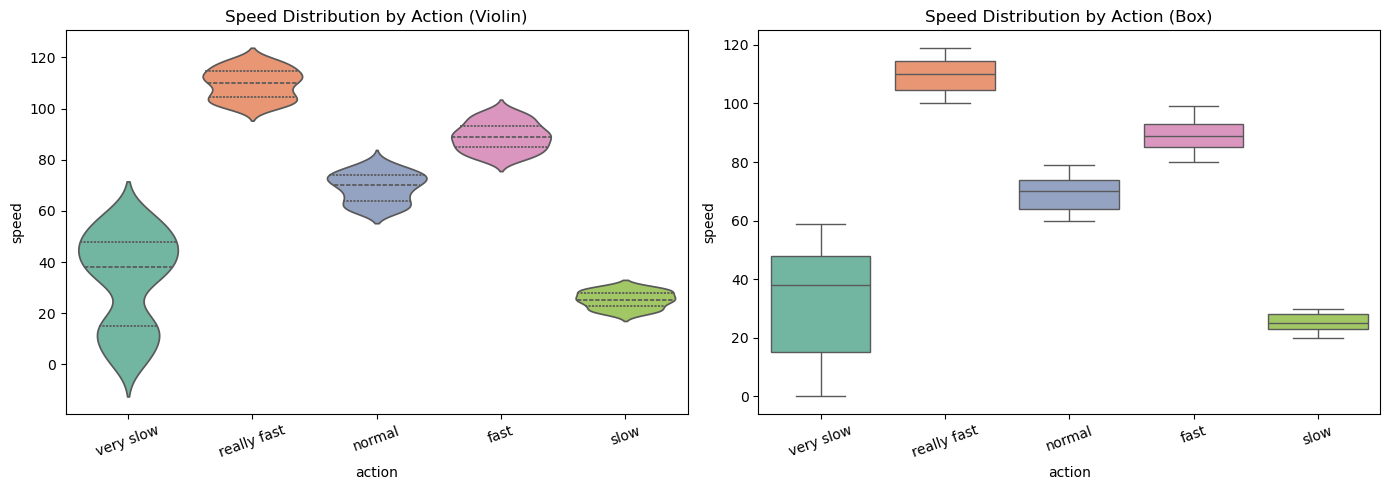

The speed feature clearly separates the action classes as expected.


In [5]:
# speed distribution - this is the key feature
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# violin plot
sns.violinplot(data=df, x='action', y='speed', palette='Set2', inner='quartile', ax=axes[0])
axes[0].set_title('Speed Distribution by Action (Violin)')
axes[0].tick_params(axis='x', rotation=20)

# box plot
sns.boxplot(data=df, x='action', y='speed', palette='Set2', ax=axes[1])
axes[1].set_title('Speed Distribution by Action (Box)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

print("The speed feature clearly separates the action classes as expected.")

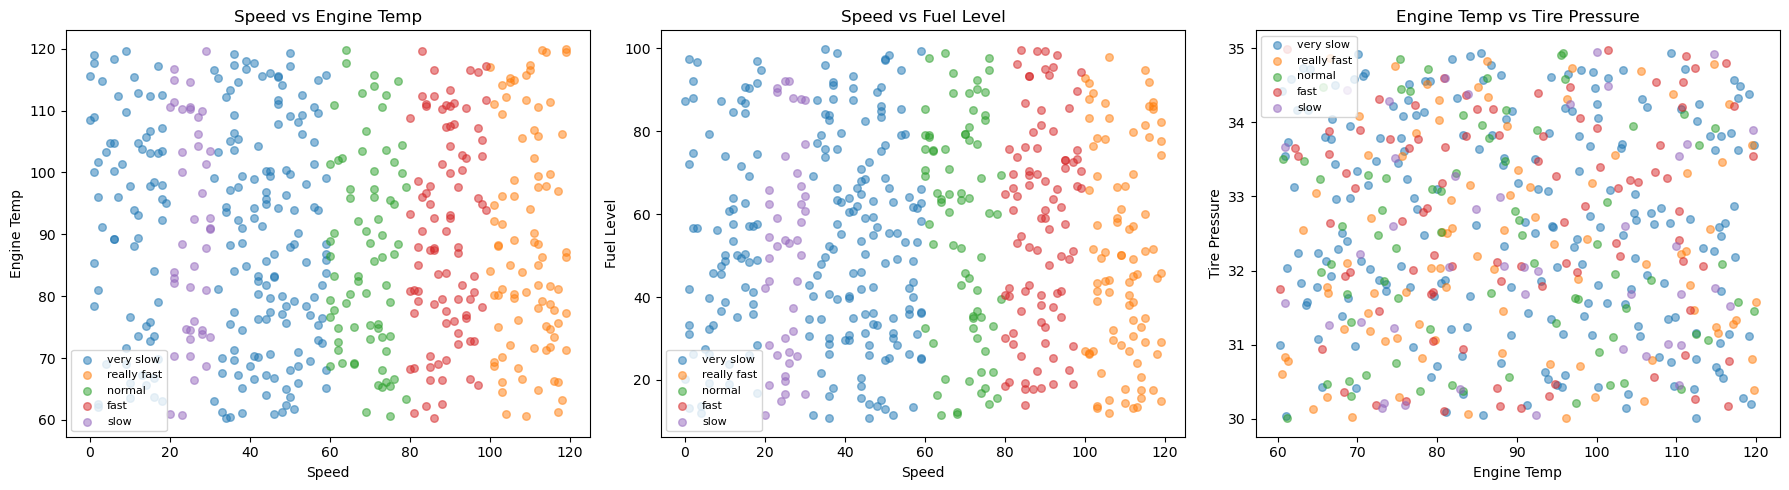

In [6]:
# scatter plots for some key feature pairs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# speed vs engine temp
for action in df['action'].unique():
    subset = df[df['action'] == action]
    axes[0].scatter(subset['speed'], subset['engine_temp'], label=action, alpha=0.5, s=30)
axes[0].set_xlabel('Speed')
axes[0].set_ylabel('Engine Temp')
axes[0].set_title('Speed vs Engine Temp')
axes[0].legend(fontsize=8)

# speed vs fuel level
for action in df['action'].unique():
    subset = df[df['action'] == action]
    axes[1].scatter(subset['speed'], subset['fuel_level'], label=action, alpha=0.5, s=30)
axes[1].set_xlabel('Speed')
axes[1].set_ylabel('Fuel Level')
axes[1].set_title('Speed vs Fuel Level')
axes[1].legend(fontsize=8)

# engine temp vs tire pressure
for action in df['action'].unique():
    subset = df[df['action'] == action]
    axes[2].scatter(subset['engine_temp'], subset['tire_pressure'], label=action, alpha=0.5, s=30)
axes[2].set_xlabel('Engine Temp')
axes[2].set_ylabel('Tire Pressure')
axes[2].set_title('Engine Temp vs Tire Pressure')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

In [7]:
# encode target and split
X = df.drop('action', axis=1)
y = df['action']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print(f"Classes: {list(le.classes_)}")

Train: 400 samples | Test: 100 samples
Classes: ['fast', 'normal', 'really fast', 'slow', 'very slow']


## 4. Training Multiple Models

In [8]:
# define all models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM': SVC(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

results = {}
predictions = {}

for name, model in models.items():
    # use scaled data for LR, SVM, KNN
    if name in ['Logistic Regression', 'SVM', 'KNN']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
    
    results[name] = {'Accuracy': acc, 'Precision': p, 'Recall': r, 'F1': f1}
    predictions[name] = y_pred

results_df = pd.DataFrame(results).T.round(4)
print("Test Set Results:")
print(results_df.sort_values('Accuracy', ascending=False))

Test Set Results:
                     Accuracy  Precision  Recall      F1
Decision Tree            1.00     1.0000    1.00  1.0000
Gradient Boosting        1.00     1.0000    1.00  1.0000
Random Forest            0.93     0.9366    0.93  0.9215
Logistic Regression      0.85     0.7868    0.85  0.8136
SVM                      0.71     0.6445    0.71  0.6686
KNN                      0.61     0.6111    0.61  0.5865


In [9]:
# detailed classification reports
for name, y_pred in predictions.items():
    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(classification_report(y_test, y_pred, target_names=le.classes_))


Logistic Regression
              precision    recall  f1-score   support

        fast       0.93      0.78      0.85        18
      normal       0.82      0.93      0.88        15
 really fast       0.94      1.00      0.97        17
        slow       0.00      0.00      0.00         9
   very slow       0.82      0.98      0.89        41

    accuracy                           0.85       100
   macro avg       0.70      0.74      0.72       100
weighted avg       0.79      0.85      0.81       100


Decision Tree
              precision    recall  f1-score   support

        fast       1.00      1.00      1.00        18
      normal       1.00      1.00      1.00        15
 really fast       1.00      1.00      1.00        17
        slow       1.00      1.00      1.00         9
   very slow       1.00      1.00      1.00        41

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.

## 5. Cross Validation Comparison

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_all_scaled = scaler.fit_transform(X)
cv_results = {}

for name, model in models.items():
    if name in ['Logistic Regression', 'SVM', 'KNN']:
        scores = cross_val_score(model, X_all_scaled, y_encoded, cv=cv, scoring='accuracy')
    else:
        scores = cross_val_score(model, X, y_encoded, cv=cv, scoring='accuracy')
    cv_results[name] = {'mean': scores.mean(), 'std': scores.std(), 'scores': scores}

# display
cv_df = pd.DataFrame({
    'Model': list(cv_results.keys()),
    'Mean CV Accuracy': [cv_results[m]['mean'] for m in cv_results],
    'Std': [cv_results[m]['std'] for m in cv_results]
}).sort_values('Mean CV Accuracy', ascending=False)

cv_df['Mean CV Accuracy'] = cv_df['Mean CV Accuracy'].map('{:.4f}'.format)
cv_df['Std'] = cv_df['Std'].map('{:.4f}'.format)
print(cv_df.to_string(index=False))

              Model Mean CV Accuracy    Std
      Decision Tree           1.0000 0.0000
  Gradient Boosting           1.0000 0.0000
      Random Forest           0.9340 0.0049
Logistic Regression           0.8320 0.0117
                SVM           0.7600 0.0190
                KNN           0.5480 0.0453


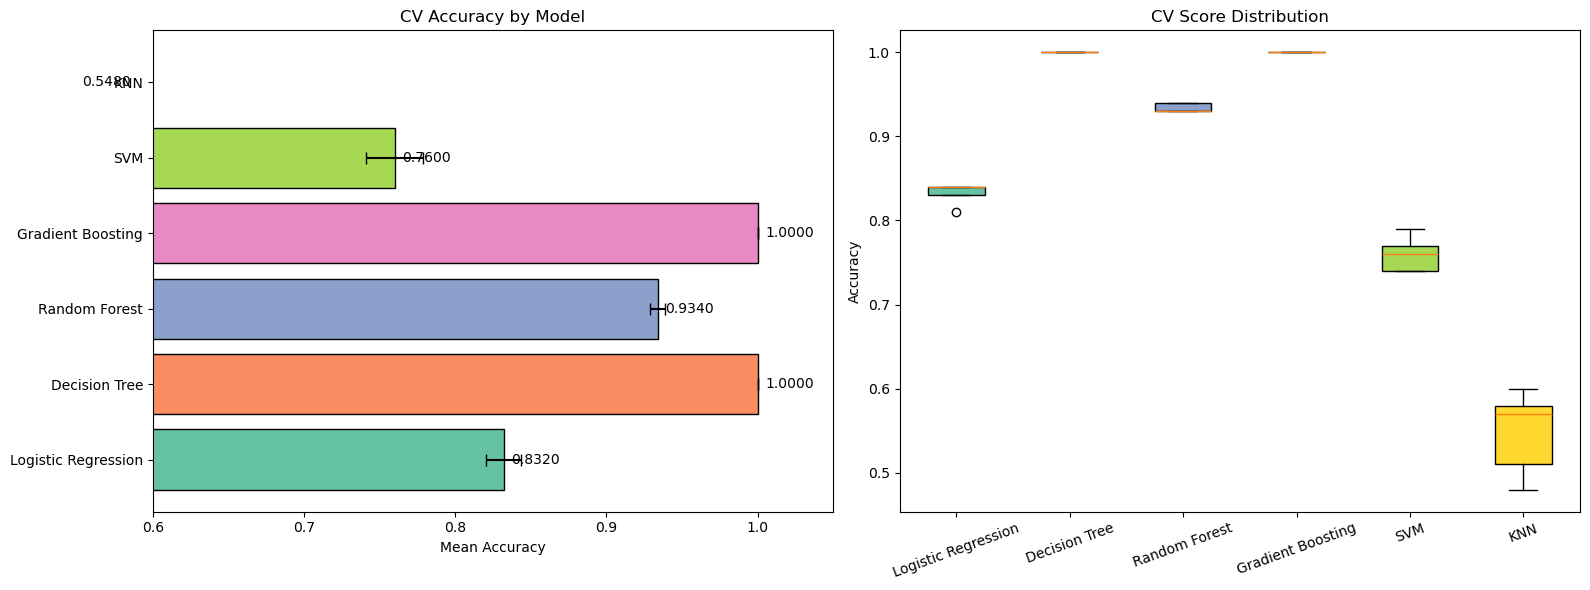

In [11]:
# visual comparison of CV results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# bar chart
names = list(cv_results.keys())
means = [cv_results[m]['mean'] for m in names]
stds = [cv_results[m]['std'] for m in names]
colors = sns.color_palette('Set2', len(names))

bars = axes[0].barh(names, means, xerr=stds, color=colors, edgecolor='black', capsize=4)
axes[0].set_xlabel('Mean Accuracy')
axes[0].set_title('CV Accuracy by Model')
axes[0].set_xlim(0.6, 1.05)
for bar, m in zip(bars, means):
    axes[0].text(m + 0.005, bar.get_y() + bar.get_height()/2, f'{m:.4f}', va='center')

# box plot
all_scores = [cv_results[m]['scores'] for m in names]
bp = axes[1].boxplot(all_scores, labels=names, patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
axes[1].set_ylabel('Accuracy')
axes[1].set_title('CV Score Distribution')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## 6. Hyperparameter Tuning

Now let me tune the top models to see if I can squeeze out better performance.

In [12]:
# tune Random Forest
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params,
                       cv=cv, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X, y_encoded)
print(f"Random Forest best: {rf_grid.best_params_}")
print(f"Best CV accuracy: {rf_grid.best_score_:.4f}")

Random Forest best: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV accuracy: 0.9420


In [13]:
# tune Gradient Boosting
gb_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2]
}

gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42), gb_params,
                       cv=cv, scoring='accuracy', n_jobs=-1)
gb_grid.fit(X, y_encoded)
print(f"Gradient Boosting best: {gb_grid.best_params_}")
print(f"Best CV accuracy: {gb_grid.best_score_:.4f}")

Gradient Boosting best: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50}
Best CV accuracy: 1.0000


In [14]:
# tune SVM
svm_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(SVC(random_state=42), svm_params,
                        cv=cv, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_all_scaled, y_encoded)
print(f"SVM best: {svm_grid.best_params_}")
print(f"Best CV accuracy: {svm_grid.best_score_:.4f}")

SVM best: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy: 0.8780


## 7. Confusion Matrices

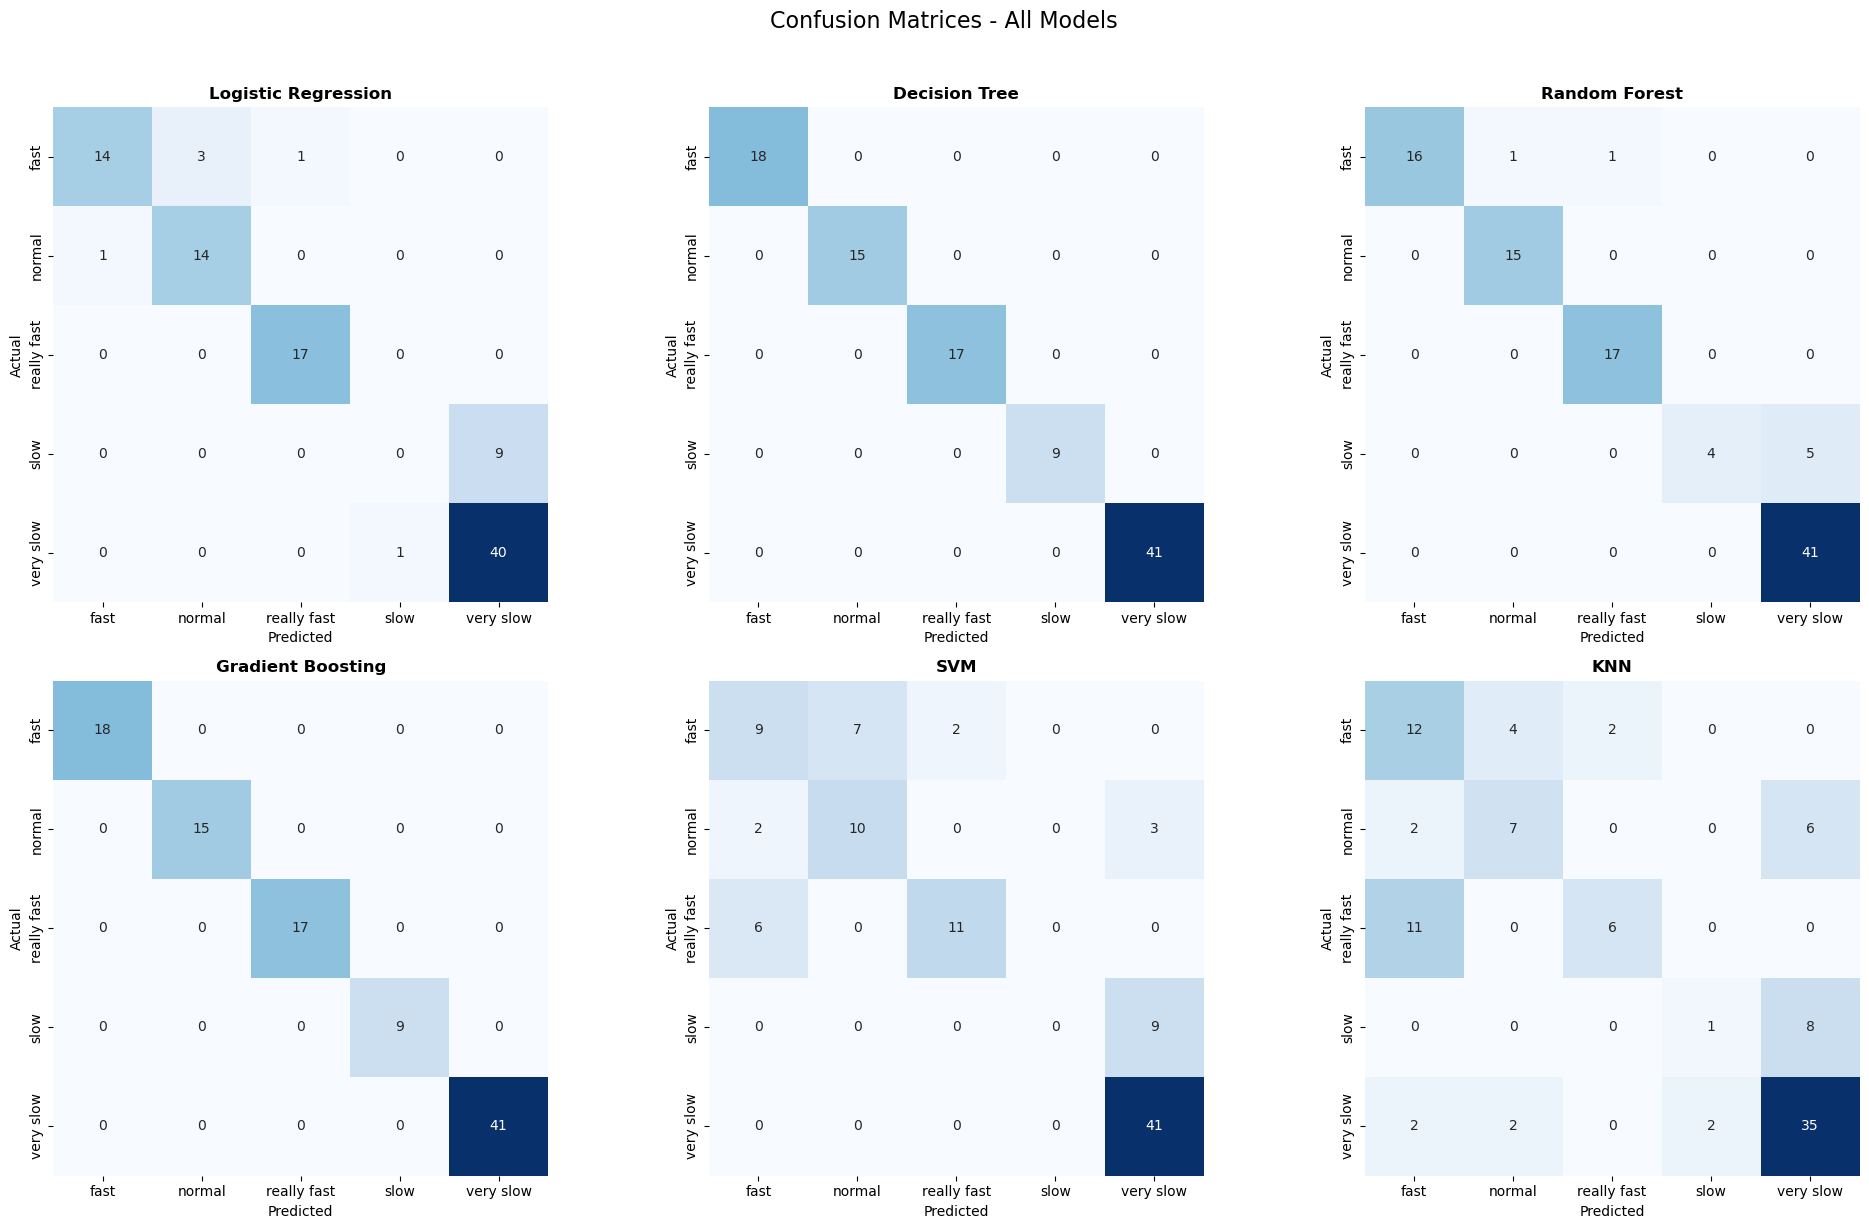

In [15]:
# confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_,
                cbar=False, square=True)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices - All Models', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 8. Final Comparison

In [16]:
# final comparison table with CV accuracy
final = pd.DataFrame(results).T
final['CV Accuracy'] = [cv_results[m]['mean'] for m in final.index]
final = final.sort_values('CV Accuracy', ascending=False)

print("=" * 65)
print("            FINAL MODEL COMPARISON")
print("=" * 65)
print(final.round(4).to_string())
print("=" * 65)

best = final['CV Accuracy'].idxmax()
print(f"\nBest model: {best} (CV Accuracy: {final.loc[best, 'CV Accuracy']:.4f})")

            FINAL MODEL COMPARISON
                     Accuracy  Precision  Recall      F1  CV Accuracy
Decision Tree            1.00     1.0000    1.00  1.0000        1.000
Gradient Boosting        1.00     1.0000    1.00  1.0000        1.000
Random Forest            0.93     0.9366    0.93  0.9215        0.934
Logistic Regression      0.85     0.7868    0.85  0.8136        0.832
SVM                      0.71     0.6445    0.71  0.6686        0.760
KNN                      0.61     0.6111    0.61  0.5865        0.548

Best model: Decision Tree (CV Accuracy: 1.0000)


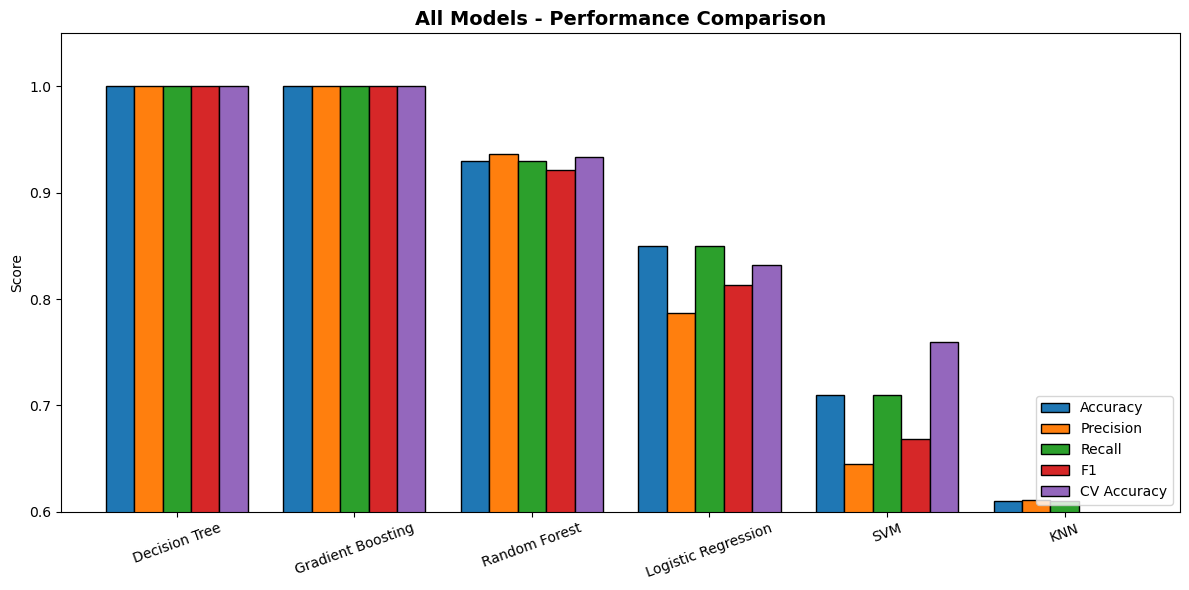

In [17]:
# visual comparison of all metrics
fig, ax = plt.subplots(figsize=(12, 6))
final.plot(kind='bar', ax=ax, edgecolor='black', width=0.8)
ax.set_title('All Models - Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.6, 1.05)
ax.legend(loc='lower right')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

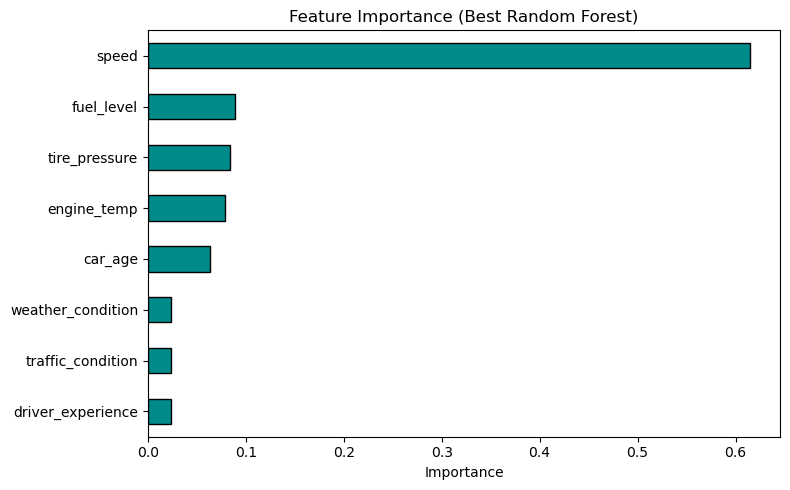

In [18]:
# feature importance from the best tree-based model
best_rf = rf_grid.best_estimator_
importance = pd.Series(best_rf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='darkcyan', edgecolor='black')
plt.title('Feature Importance (Best Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## Summary

**What I found:**
- Tree-based models (Random Forest, Gradient Boosting, Decision Tree) performed the best, mostly because the decision boundaries are axis-aligned (speed thresholds)
- Logistic Regression and SVM struggled a bit because the class boundaries aren't perfectly linear
- KNN did okay but not as well as the ensemble methods
- Speed dominates the feature importance - the other features add some noise but don't help much

**Key takeaways:**
- For this kind of problem where the target is defined by simple rules on one feature, tree-based models naturally excel
- Hyperparameter tuning gave small improvements but the baseline was already strong
- Cross validation confirms the results are reliable

**If I had real-world data** (not synthetic), the other features like engine_temp, weather, and traffic would probably matter more.